# Same computation, different measured complexity

**Question:** can we change a network's measured “complexity” without changing what it computes?

We'll start with one ReLU you can calculate by hand, then reproduce a counterexample from our modular-addition experiments. No training or GPU is needed. The notebook uses NumPy and an existing, checked-in checkpoint.

**Before running:** predict which of these will change when we multiply a hidden unit's incoming weights by a positive number and divide its outgoing weights by the same number:

- its activation;
- the network's output;
- the parameter norm;
- the number of bits our pruning/quantization procedure reports.

Write down your guesses. Then run the cells in order. The saved outputs are a worked answer; **Restart Kernel and Clear All Outputs** gives you a fresh pass.

This is an educational reconstruction of an already-discovered negative result, not a new preregistered experiment. One counterexample can disprove invariance; it cannot tell us how common the issue is.

In [1]:
import os
for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS",
             "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"  # before NumPy loads; restart the kernel if necessary

import csv
import hashlib
import json
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "experiment.py").is_file() and (p / "research").is_dir())
HERE = ROOT / "walkthroughs/01-rescaling"
OUT = HERE / "outputs"
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT))

# Reuse the exact research codec; we are auditing it, not replacing it.
from experiment import compress, fidelity, forward

plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#0072B2", "#D55E00"

def save_figure(fig, name):
    for ext in ("png", "svg"):
        fig.savefig(OUT / f"{name}.{ext}", facecolor="white")

def save_rows(name, rows):
    with (OUT / name).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

print(f"Python {platform.python_version()}, NumPy {np.__version__}, "
      f"Matplotlib {matplotlib.__version__}")


Python 3.12.14, NumPy 2.3.5, Matplotlib 3.11.2


## 1. One neuron: move the scale through a ReLU

Our first network is

\[
f(x)=v\,\mathrm{ReLU}(ux), \qquad u=2,\quad v=3.
\]

Here \(\mathrm{ReLU}(z)=\max(z,0)\). For any **positive** \(c\),

\[
\frac{v}{c}\,\mathrm{ReLU}(cux)
= \frac{v}{c}\,c\,\mathrm{ReLU}(ux)
= f(x).
\]

The activation gets bigger; its contribution to the output stays the same. This is an exact algebraic identity, not an approximate learned behavior.

Try \(x=1\) and \(c=4\) by hand. Then ask: does \(u^2+v^2\), the squared parameter norm, stay the same?

In [2]:
relu = lambda x: np.maximum(x, 0)
u, v, c = 2.0, 3.0, 4.0
x = np.linspace(-2, 2, 201)
original = v * relu(u * x)
rescaled = (v / c) * relu((c * u) * x)

np.testing.assert_allclose(rescaled, original, rtol=1e-14, atol=1e-14)
print(f"At x=1: activation {relu(u):g} -> {relu(c*u):g}; "
      f"output {v*relu(u):g} -> {(v/c)*relu(c*u):g}")
print(f"Squared parameter norm: {u*u + v*v:g} -> "
      f"{(c*u)**2 + (v/c)**2:g}")

# Negative control: scaling only the input does NOT preserve the output.
uncompensated = v * relu(c * u * x)
assert not np.allclose(uncompensated, original)
# Positive c matters: ReLU(-z) is generally not -ReLU(z).
assert not np.allclose((-v) * relu(-u * x), original)


At x=1: activation 2 -> 8; output 6 -> 6
Squared parameter norm: 13 -> 64.5625


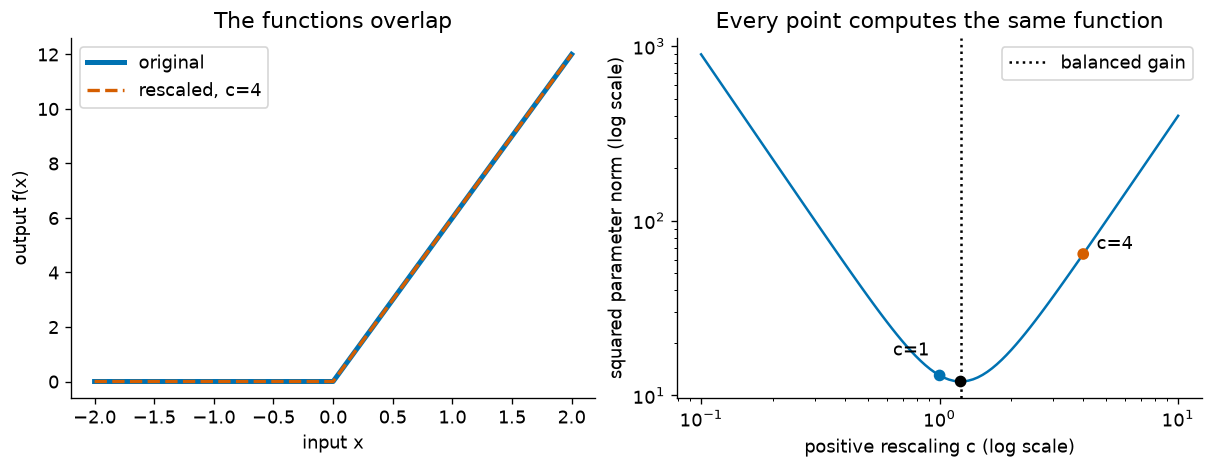

In [3]:
gains = np.geomspace(0.1, 10, 101)
norm_squared = (gains*u)**2 + (v/gains)**2
best_gain = np.sqrt(abs(v/u))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].plot(x, original, color=BLUE, lw=3, label="original")
axes[0].plot(x, rescaled, color=ORANGE, ls="--", lw=2, label="rescaled, c=4")
axes[0].set(xlabel="input x", ylabel="output f(x)", title="The functions overlap")
axes[0].legend()
axes[1].plot(gains, norm_squared, color=BLUE)
axes[1].scatter([1, c, best_gain],
                [(u)**2+v**2, (c*u)**2+(v/c)**2, 2*abs(u*v)],
                color=[BLUE, ORANGE, "black"], marker="o", zorder=3)
axes[1].annotate("c=1", (1, u*u+v*v), xytext=(-28, 12), textcoords="offset points")
axes[1].annotate("c=4", (c, (c*u)**2+(v/c)**2), xytext=(8, 3), textcoords="offset points")
axes[1].axvline(best_gain, color="black", ls=":", label="balanced gain")
axes[1].set(xscale="log", yscale="log", xlabel="positive rescaling c (log scale)",
            ylabel="squared parameter norm (log scale)",
            title="Every point computes the same function")
axes[1].legend()
save_figure(fig, "01-one-neuron")
plt.show()
save_rows("one-neuron.csv", [
    {"gain": float(g), "squared_parameter_norm": float(n)}
    for g, n in zip(gains, norm_squared)
])


The left panel shows identical functions. The right panel contains **different representations of that one function**, not different training runs. Both axes on the right are logarithmic.

The squared norm changes from 13 to 64.5625. It can become arbitrarily large along this family. That does **not** make norm useless: a regularizer can favor one parameterization over another. It does mean that raw parameter norm is not solely a property of the computed function.

**Pause:** would observing a falling norm during training, by itself, establish that the algorithm became simpler? What else would you need to measure?

## 2. The same symmetry in our modular-addition model

For input tokens \(a,b\), our actual model computes

\[
h_j(a,b)=\mathrm{ReLU}(U_{aj}+V_{bj}),\qquad
\ell_k(a,b)=\sum_j h_j(a,b)W_{jk}.
\]

The \(\ell_k\) are logits: scores for each possible output label. Multiply **both** input columns \(U_{:j},V_{:j}\) by \(c_j>0\), and divide output row \(W_{j:}\) by \(c_j\). Each contribution \(h_jW_{jk}\) is unchanged.

We use run **e1-co-add-w128-i30000-a1**, step **50,000**: 31 labels, 128 hidden units, 30% nominal training share. This checkpoint fits training data but fails to generalize. That failure does not prevent it from serving as a counterexample about a measurement.

The next cell checks the bytes before loading them. It uses repository artifacts, not a new training run.

In [4]:
SOURCE_COMMIT = "9e56faf915c85a8aefa90f662e46ce94c474ce75"
RUN_ID = "e1-co-add-w128-i30000-a1"
run = ROOT / "research/coordinator/runs" / RUN_ID
expected_hashes = {
    "checkpoint_050000.npz": "326cfc1ec1583d94993b2b3b289cd3bb9081f64a0ece5060a817375aadd111b4",
    "data.npz": "3fa3dbf0c04e1c6033f36d72a039d402aa244a685cd75791cd5ebb46f6571857",
}
for name, expected in expected_hashes.items():
    actual = hashlib.sha256((run / name).read_bytes()).hexdigest()
    assert actual == expected, f"Different source artifact: {name}"
codec_source_hash = hashlib.sha256((ROOT / "experiment.py").read_bytes()).hexdigest()
assert codec_source_hash == "0355ab099bca9bc403bd9b9060e7cb3b1a7f2b73433b6a208af12df9518b749a", (
    "The research implementation changed. Review the diff before updating this pin."
)

with np.load(run / "checkpoint_050000.npz", allow_pickle=False) as archive:
    weights = [archive[key].copy() for key in ("U", "V", "W")]
with np.load(run / "data.npz", allow_pickle=False) as archive:
    data = {key: archive[key].copy() for key in archive.files}
a, b, labels = data["a"], data["b"], data["y"]
masks = [data[key] for key in ("train", "cal", "audit")]
assert len(a) == 31**2
assert len(np.unique(np.concatenate(masks))) == len(a)
base_logits = forward(weights, a, b)[0]
for name, ix in zip(("train", "calibration", "audit"), masks):
    print(f"{name:11s}: {len(ix):3d} examples, "
          f"accuracy {np.mean(base_logits[ix].argmax(1) == labels[ix]):.3f}")


train      : 299 examples, accuracy 1.000
calibration: 118 examples, accuracy 0.000
audit      : 544 examples, accuracy 0.000


## 3. Reproduce one published rescaling

We deliberately select a known counterexample from the exploratory sweep: random seed **33200**, log-gain SD **0.25**, draw **8** (zero-based, after the 16 draws at SD 0.1). This is **selected for illustration**, not an estimate of the frequency of this effect.

We'll check all 961 input pairs, not merely whether the winning labels match. Equal argmax predictions alone would allow the scores to change substantially.

**Predict:** should the hidden activation matrix be identical? Should the output scores be identical?

In [5]:
def rescale(weights, gains):
    U, V, W = weights
    gains = np.asarray(gains, dtype=float)
    if gains.shape != (U.shape[1],) or not np.all(np.isfinite(gains) & (gains > 0)):
        raise ValueError("Need one finite, positive gain per hidden unit")
    return [U * gains, V * gains, W / gains[:, None]]

rng = np.random.default_rng(33200)
for _ in range(16):  # preceding sigma=0.1 draws in the published sweep
    rng.standard_normal(128)
for _ in range(9):   # sigma=0.25 draws 0 through 8
    gains = np.exp(0.25 * rng.standard_normal(128))
changed = rescale(weights, gains)
changed_logits = forward(changed, a, b)[0]

np.testing.assert_allclose(changed_logits, base_logits, rtol=1e-12, atol=1e-12)
np.testing.assert_array_equal(changed_logits.argmax(1), base_logits.argmax(1))
np.testing.assert_allclose(
    forward(changed, a, b)[1], forward(weights, a, b)[1] * gains,
    rtol=1e-12, atol=1e-12
)
print(f"Gains range from {gains.min():.3f} to {gains.max():.3f}")
print(f"Max absolute logit difference: {np.max(np.abs(changed_logits-base_logits)):.3g}")
print("Predictions agree on every input; activations scale as predicted.")


Gains range from 0.578 to 2.064
Max absolute logit difference: 7.11e-15
Predictions agree on every input; activations scale as predicted.


## 4. Ask the original codec how long each representation is

The research procedure tries retaining \(k\) hidden units and quantizing each matrix with \(q\in\{4,8,16,64\}\) bits per weight. It uses one maximum-absolute-value scale per matrix. For \(q<64\), it rounds weights onto a uniform grid; \(q=64\) keeps them unchanged.

A candidate must preserve **each** of training and calibration prediction agreement at ≥99% and centered-logit relative squared error at ≤1%. The procedure then chooses the shortest passing candidate. The audit split is evaluated afterward.

The reported length is

\[
264 + 3pkq\quad\text{bits}.
\]

The 264-bit header describes dimensions, precision and scales under a fixed decoder. This is a **specified coding estimate**, not the size of a ZIP file and not the shortest program computing the function.

We call the existing \`experiment.compress\` unchanged. This reproduces its behavior; it is not an independent validation of every codec implementation detail.

**Predict:** can rescaling change rounding errors even though the unquantized functions are identical?

In [6]:
raw_codecs = [compress(w, a, b, masks) for w in (weights, changed)]
for name, result in zip(("original", "rescaled"), raw_codecs):
    print(f"{name:9s}: {result['bits']:,} bits, "
          f"k={result['k']} units, q={result['q']} bits/weight")
assert [result["bits"] for result in raw_codecs] == [95496, 190728], (
    "Published counterexample did not reproduce; inspect fidelity thresholds."
)
assert [result["k"] for result in raw_codecs] == [128, 128]

def prune_scores(w):
    U, V, W = w
    return (np.linalg.norm(U, axis=0) + np.linalg.norm(V, axis=0)) * np.linalg.norm(W, axis=1)

np.testing.assert_allclose(prune_scores(weights), prune_scores(changed),
                           rtol=1e-12, atol=1e-12)
np.testing.assert_array_equal(np.argsort(-prune_scores(weights), kind="stable"),
                              np.argsort(-prune_scores(changed), kind="stable"))
print("The pruning order is unchanged; both chosen candidates retain all units.")


original : 95,496 bits, k=128 units, q=8 bits/weight
rescaled : 190,728 bits, k=128 units, q=16 bits/weight
The pruning order is unchanged; both chosen candidates retain all units.


The codec selected 8-bit weights for the original and 16-bit weights for the rescaled copy. The doubling comes from a discrete precision choice, with the same 128 units retained.

Let's look at the rejected 8-bit candidate directly. The cell below uses the codec's same per-matrix grid and unit ordering. “Agreement” is agreement **with the original network's predictions**, not with correct modular sums. A perfect copy of a bad predictor is still a bad predictor.

In [7]:
def quantize_full_model(w, bits=8):
    order = np.argsort(-prune_scores(w), kind="stable")
    ordered = [w[0][:, order], w[1][:, order], w[2][order]]
    levels = 2**(bits-1) - 1
    scales = [max(float(np.abs(matrix).max()), 1e-30) for matrix in ordered]
    quantized = [np.rint(matrix/scale*levels)/levels*scale
                 for matrix, scale in zip(ordered, scales)]
    return quantized, scales

rounding_rows = []
for name, w in (("original", weights), ("rescaled", changed)):
    quantized, scales = quantize_full_model(w)
    logits = forward(quantized, a, b)[0]
    reference = forward(w, a, b)[0]
    print(f"{name} 8-bit grid spacings (U, V, W):",
          [round(scale/127, 6) for scale in scales])
    for split, ix in zip(("train", "calibration", "audit"), masks):
        f = fidelity(logits, reference, ix)
        row = {"representation": name, "split": split, **f,
               "passes_fidelity_thresholds": f["agreement"] >= .99 and f["relative_mse"] <= .01}
        rounding_rows.append(row)
        print(f"  {split:11s}: agreement={f['agreement']:.4f}, "
              f"relative MSE={f['relative_mse']:.6f}, "
              f"passes={row['passes_fidelity_thresholds']}")
save_rows("eight-bit-fidelity.csv", rounding_rows)


original 8-bit grid spacings (U, V, W): [0.005924, 0.00594, 0.006691]
  train      : agreement=1.0000, relative MSE=0.000014, passes=True
  calibration: agreement=1.0000, relative MSE=0.000017, passes=True
  audit      : agreement=0.9982, relative MSE=0.000019, passes=True
rescaled 8-bit grid spacings (U, V, W): [0.010697, 0.009871, 0.01095]
  train      : agreement=1.0000, relative MSE=0.000044, passes=True
  calibration: agreement=0.9831, relative MSE=0.000059, passes=False
  audit      : agreement=0.9890, relative MSE=0.000060, passes=False


In this example, 8-bit quantization flips **2 of 118 calibration predictions** after rescaling: agreement falls to 98.3%, below the 99% gate. Relative squared error still passes. The codec jumps to its next available precision, 16 bits. A discrete acceptance threshold amplifies a small rounding difference into a nearly twofold code-length difference. The audit numbers are descriptive; they do not select the precision.

## 5. Remove this freedom with a balancing convention

Let \(A_j=\|U_{:j}\|^2+\|V_{:j}\|^2\) and \(B_j=\|W_{j:}\|^2\). Along a unit's rescaling family its squared norm is

\[
N_j(c)=A_jc^2+B_j/c^2.
\]

For \(A_j,B_j>0\), the minimum occurs at

\[
c_j=(B_j/A_j)^{1/4}.
\]

At that point incoming and outgoing squared norms are equal. Balancing every positively rescaled copy therefore recovers the same representative, up to floating-point error.

Our short function explicitly requires nonzero incoming and outgoing norms. A unit with a zero side needs a separate convention; silently dividing by zero would not establish invariance.

**Predict:** will balancing the original and rescaled checkpoint produce the same weights? Will their codec estimates agree?

In [8]:
def balance(w):
    U, V, W = w
    incoming = np.sum(U**2, axis=0) + np.sum(V**2, axis=0)
    outgoing = np.sum(W**2, axis=1)
    if np.any(incoming == 0) or np.any(outgoing == 0):
        raise ValueError("This walkthrough's balance convention requires nonzero sides")
    return rescale(w, (outgoing/incoming)**0.25)

balanced = balance(weights)
balanced_changed = balance(changed)
for left, right in zip(balanced, balanced_changed):
    np.testing.assert_allclose(left, right, rtol=1e-12, atol=1e-12)
for left, right in zip(balanced, balance(balanced)):
    np.testing.assert_allclose(left, right, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(forward(balanced, a, b)[0], base_logits,
                           rtol=1e-12, atol=1e-12)

variants = [weights, changed, balanced, balanced_changed]
names = ["original", "rescaled", "balanced original", "balanced rescaled"]
codec_results = raw_codecs + [compress(w, a, b, masks) for w in variants[2:]]
assert codec_results[2]["bits"] == codec_results[3]["bits"] == 95496

results = []
for name, w, result in zip(names, variants, codec_results):
    error = float(np.max(np.abs(forward(w, a, b)[0] - base_logits)))
    assert error < 1e-10
    results.append({"representation": name, "parameter_norm": float(np.sqrt(sum(
        np.sum(matrix**2) for matrix in w))), "codec_bits": result["bits"],
        "retained_units": result["k"], "bits_per_weight": result["q"],
        "max_abs_logit_error": error})
save_rows("checkpoint-comparison.csv", results)
display(Markdown("| Representation | Norm | Codec bits | Max logit error |\n"
                 "|---|---:|---:|---:|\n" + "\n".join(
    f"| {r['representation']} | {r['parameter_norm']:.3f} | {r['codec_bits']:,} "
    f"| {r['max_abs_logit_error']:.2g} |" for r in results)))


| Representation | Norm | Codec bits | Max logit error |
|---|---:|---:|---:|
| original | 60.338 | 95,496 | 0 |
| rescaled | 63.494 | 190,728 | 7.1e-15 |
| balanced original | 60.049 | 95,496 | 7.1e-15 |
| balanced rescaled | 60.049 | 95,496 | 1.1e-14 |

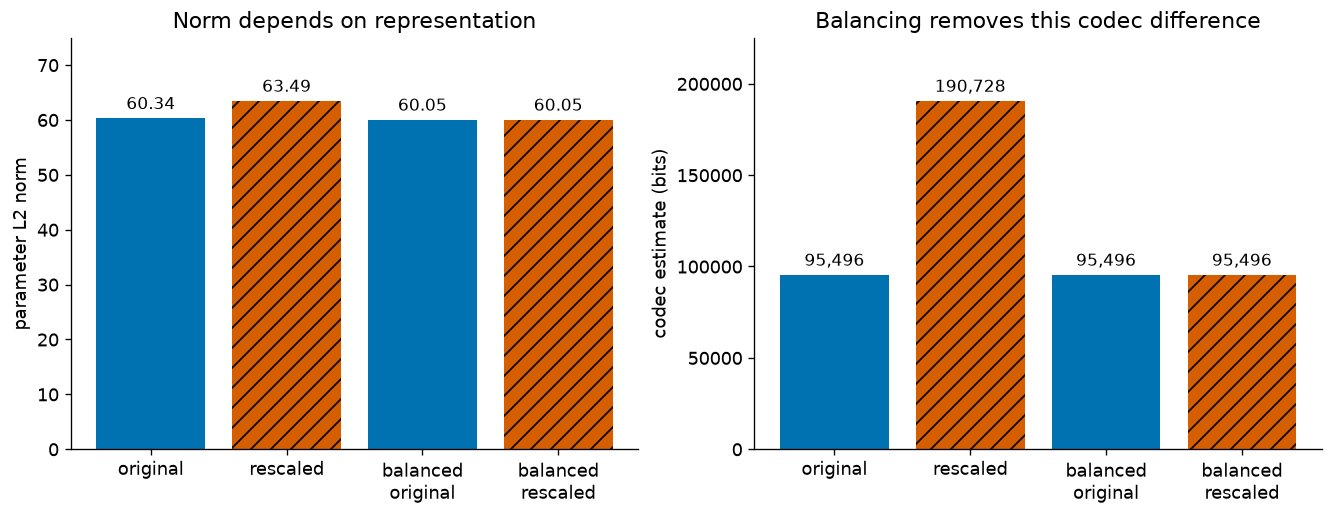

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
positions = np.arange(4)
colors = [BLUE, ORANGE, BLUE, ORANGE]
for ax, key, ylabel, title in (
    (axes[0], "parameter_norm", "parameter L2 norm", "Norm depends on representation"),
    (axes[1], "codec_bits", "codec estimate (bits)", "Balancing removes this codec difference"),
):
    bars = ax.bar(positions, [r[key] for r in results], color=colors)
    for bar, hatch in zip(bars, ["", "//", "", "//"]):
        bar.set_hatch(hatch)
    ax.set(xticks=positions, xticklabels=["original", "rescaled", "balanced\noriginal", "balanced\nrescaled"],
           ylabel=ylabel, title=title)
    ax.set_ylim(0, max(r[key] for r in results)*1.18)
    ax.bar_label(bars, labels=[f"{r[key]:.2f}" if key == "parameter_norm" else f"{r[key]:,}" for r in results], padding=3, fontsize=10)
save_figure(fig, "02-checkpoint-comparison")
plt.show()


All four representations compute the same logits to numerical tolerance. The chart's bars start at zero; hatching distinguishes rescaled copies. These are four versions of **one checkpoint**, not four independent replicates.

**What we have established**

- This raw coding procedure is sensitive to a function-preserving change of representation.
- For the selected checkpoint, its reported length changes from 95,496 to 190,728 bits.
- Balancing removes the positive hidden-unit rescaling ambiguity in this example.

**What we have not established**

- That gradient descent has no simplicity preference.
- That compression is useless, or that every codec has this defect.
- That balancing removes every equivalent representation.
- That a balanced codec measures shortest program length, functional importance, or reusable computation.

A norm-sensitive regularizer or optimizer can care about parameterization even when the function is unchanged. This notebook edits analysis copies **after training**. Continuing training from them would be a different experiment, involving optimizer state as well as weights.

**Try explaining the result without the word “complexity.”** For example: “The same input-output map requires different precision under this particular weight-rounding procedure.” What additional evidence would justify saying more?

## 6. A small next exercise

Change \`c\` in the one-neuron example, predict the two norms, and rerun that section. Then derive the minimum of \(Ac^2+B/c^2\) yourself.

For the trained model, uniform gains on *every* hidden unit are an interesting contrast to unequal per-unit gains: with a per-matrix quantizer, uniform scaling can cancel through the quantization scales too. Predict the outcome before trying it. Preserve the reproduction above and label any new trials separately.

The notebook writes two figures (PNG/SVG), three CSV tables, and a provenance record under \`outputs/\`. It performs no training and makes no changes to the source checkpoint.

In [10]:
provenance = {
    "purpose": "educational reconstruction; selected published counterexample, no training",
    "source_commit": SOURCE_COMMIT,
    "run_id": RUN_ID,
    "checkpoint_step": 50000,
    "artifact_sha256": expected_hashes,
    "experiment_py_sha256": codec_source_hash,
    "rescaling": {"seed": 33200, "sigma": 0.25, "draw_zero_based": 8,
                  "preceding_sigma_0_1_draws": 16},
    "python": platform.python_version(), "numpy": np.__version__,
    "matplotlib": matplotlib.__version__, "platform": platform.platform(),
    "lock_sha256": hashlib.sha256((HERE/"uv.lock").read_bytes()).hexdigest(),
    "results": results,
}
(OUT/"provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("All reconstruction checks passed. Figures, tables and provenance:", OUT)


All reconstruction checks passed. Figures, tables and provenance: /workspace/scratch/ff3b7b221e8b/modest-complexity-walkthrough/walkthroughs/01-rescaling/outputs


## Source trail

- [Published rescaling sweep and interpretation](https://github.com/bfaber-centaur/modest-complexity/blob/9e56faf915c85a8aefa90f662e46ce94c474ce75/research/mechanisms/README.md), Packet 2. This example is selected from that sweep.
- [Original sweep code](https://github.com/bfaber-centaur/modest-complexity/blob/9e56faf915c85a8aefa90f662e46ce94c474ce75/research/mechanisms/freq.py).
- [Balancing analysis](https://github.com/bfaber-centaur/modest-complexity/blob/9e56faf915c85a8aefa90f662e46ce94c474ce75/research/mechanisms/gauge.py).
- [Codec under examination](https://github.com/bfaber-centaur/modest-complexity/blob/9e56faf915c85a8aefa90f662e46ce94c474ce75/experiment.py), function \`compress\`.
- [Checkpoint and provenance](https://github.com/bfaber-centaur/modest-complexity/tree/9e56faf915c85a8aefa90f662e46ce94c474ce75/research/coordinator/runs/e1-co-add-w128-i30000-a1).

The ReLU identity and balancing minimum are derived above; they do not depend on accepting a literature narrative about grokking.